# 5. Final comparison and held-out test
The test set was used **once**, for the configuration selected by CV.

In [1]:
from pathlib import Path
import json, pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
ROOT = Path.cwd() if (Path.cwd()/'data').exists() else Path.cwd().parent
RES = ROOT/'results'; sns.set_theme(style='whitegrid')
s = pd.read_csv(RES/'summary.csv'); s.head(8)[['rank','model','condition','cv_accuracy_mean','cv_accuracy_std','cv_recall_phish_mean','cv_roc_auc_mean']].round(4)

,rank,model,condition,cv_accuracy_mean,cv_accuracy_std,cv_recall_phish_mean,cv_roc_auc_mean
0,1,XGBoost,Original 30,0.9500,0.0062,0.9487,0.9922
1,2,Random Forest,Original 30,0.9440,0.0080,0.9412,0.9887
2,3,Gradient Boosting,Original 30,0.9438,0.0096,0.9395,0.9887
3,4,Stacking,Original 30,0.9395,0.0107,0.9416,0.9859
4,5,Random Forest,SelectKBest 15,0.9382,0.0124,0.9346,0.9835
5,6,Gradient Boosting,SelectKBest 15,0.9380,0.0109,0.9304,0.9862
6,7,SVM RBF,Original 30,0.9374,0.0107,0.9263,0.9826
7,8,SVM RBF,PCA 95%,0.9374,0.0106,0.9263,0.9824


In [2]:
t = json.load(open(RES/'final_test_metrics.json')); pd.Series(t)

selected_model                                                     XGBoost
feature_condition                                              Original 30
tuned                                                                False
selection_metric                       5-fold CV accuracy on training data
test_accuracy                                                     0.952137
test_precision_weighted                                           0.952147
test_recall_weighted                                              0.952137
test_f1_weighted                                                  0.952131
test_roc_auc                                                      0.993266
test_precision_phish                                              0.950658
test_recall_phish                                                 0.956954
test_f1_phish                                                     0.953795
phish_caught                                                           578
phish_missed             

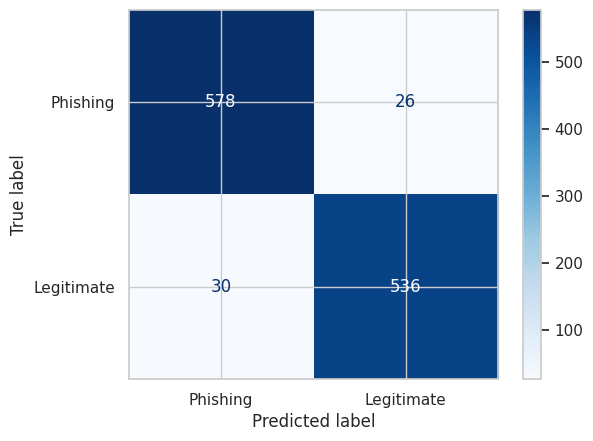

In [3]:
tp = pd.read_csv(RES/'test_predictions.csv')
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
ConfusionMatrixDisplay(confusion_matrix(tp.y_true, tp.y_pred), display_labels=['Phishing','Legitimate']).plot(cmap='Blues'); plt.show()

In [4]:
pi = pd.read_csv(RES/'permutation_importance.csv').head(10); pi

,feature,importance,std
0,url_of_anchor,0.123248,0.003799
1,sslfinal_state,0.107521,0.005882
2,prefix_suffix,0.021880,0.003225
3,web_traffic,0.020855,0.001279
4,links_pointing_to_page,0.016923,0.003561
5,having_sub_domain,0.016239,0.002756
6,links_in_tags,0.016068,0.003642
7,having_ip_address,0.013162,0.001919
8,sfh,0.012308,0.002626
9,url_length,0.005299,0.001470


**Conclusion:** XGBoost on all 30 features is selected and reaches about 95% accuracy and ~96% phishing recall on unseen data, with test accuracy matching CV (no overfitting from selection). The most important features are listed above. Dimensionality reduction did not beat the full feature set for the best model, an honest negative result.